# Project 09 on Fashion-MNIST Classification with a Fully Connected Neural Network

This notebook classifies 28 × 28 grayscale clothing images from **Fashion-MNIST** (Zalando Research) into 10 categories using a small artificial neural network built in **PyTorch**.

| | |
|---|---|
| Training images | 60,000 |
| Test images | 10,000 |
| Image size | 28 × 28 (784 pixels) |
| Classes | 10 perfectly balanced |

The data is read from the Kaggle CSV files in `datasets/` (one `label` column + 784 pixel columns).

**Contents**
1. Data exploration and preprocessing
2. Building and training the network (784 → 128 → 10)
3. Final evaluation on the test set and error analysis
4. Conclusion

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_fscore_support)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = "datasets"
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("PyTorch", torch.__version__)

PyTorch 2.15.0+cpu


---
## Task 1 Data Exploration and Preprocessing

### 1.1 Load the data
We load the official Kaggle CSV files into pandas. Each row holds one 28 × 28 image as a label plus 784 raw pixel values in the range 0 to 255.


In [2]:
train_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_test.csv")

print("Train CSV:", train_df.shape, "| Test CSV:", test_df.shape)
train_df.head()

Train CSV: (60000, 785) | Test CSV: (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Separate labels from pixels (raw uint8 values 0-255)
y_train_full = train_df["label"].to_numpy()
X_train_full = train_df.drop(columns="label").to_numpy(dtype=np.uint8)
y_test = test_df["label"].to_numpy()
X_test = test_df.drop(columns="label").to_numpy(dtype=np.uint8)

print("Pixel range:", X_train_full.min(), "to", X_train_full.max())

Pixel range: 0 to 255


### 1.2 One sample image per class
To sanity-check the data we plot the first training image from each class. This confirms the labels are correct and shows how visually similar some clothing categories are.


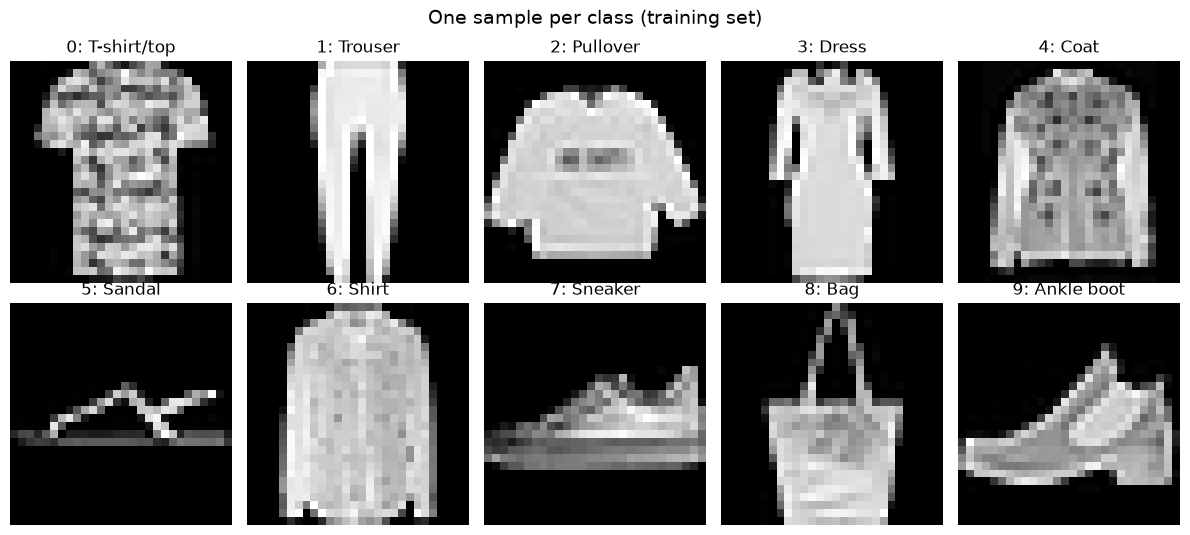

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for cls, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == cls)[0][0]           # first image of this class
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"{cls}: {CLASS_NAMES[cls]}")
    ax.axis("off")
fig.suptitle("One sample per class (training set)", fontsize=14)
plt.tight_layout()
plt.show()

### 1.3 Class balance check
We count the images per class in both the training and test sets. A balanced dataset lets us use plain accuracy as a fair overall metric.


,class,train count,test count
0,T-shirt/top,6000,1000
1,Trouser,6000,1000
2,Pullover,6000,1000
3,Dress,6000,1000
4,Coat,6000,1000
5,Sandal,6000,1000
6,Shirt,6000,1000
7,Sneaker,6000,1000
8,Bag,6000,1000
9,Ankle boot,6000,1000


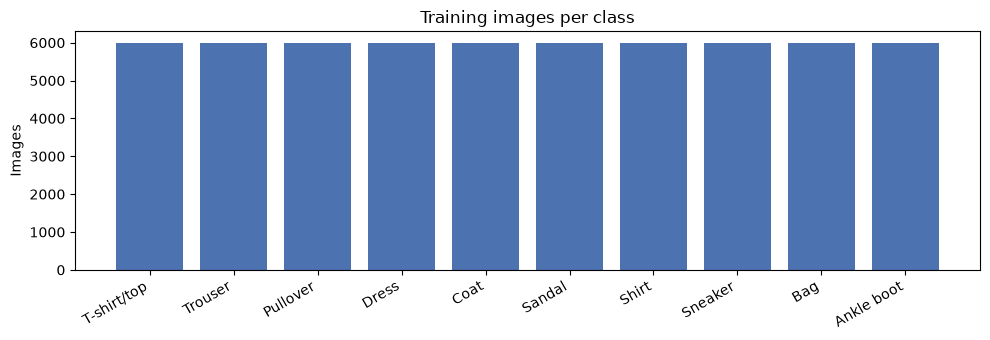

Perfectly balanced: True


In [5]:
balance = pd.DataFrame({
    "class": CLASS_NAMES,
    "train count": np.bincount(y_train_full, minlength=10),
    "test count": np.bincount(y_test, minlength=10),
})
display(balance)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(CLASS_NAMES, balance["train count"], color="#4C72B0")
ax.set_ylabel("Images")
ax.set_title("Training images per class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

is_balanced = balance["train count"].nunique() == 1 and balance["test count"].nunique() == 1
print("Perfectly balanced:", is_balanced)

Every class has exactly **6,000 training** and **1,000 test** images so the dataset is perfectly balanced. That means plain accuracy is a fair headline metric and we don't need class weighting or resampling.

### 1.4 Scaling and flattening with the validation split

* **Scaling** means dividing by 255 so every pixel lies in [0, 1].
* **Flattening** is straightforward because the CSV already stores each image as a row of 784 values so each sample is already a 784-feature vector. (Images would otherwise be reshaped from 28 × 28 to 784.)
* **Validation split** means holding out 10,000 of the 60,000 training images (stratified so each class still has an equal share). The test set stays untouched until Task 3.

In [6]:
# Scale to [0, 1]
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# Flatten (no-op for CSV data, shown explicitly for clarity)
X_train_full = X_train_full.reshape(len(X_train_full), -1)
X_test = X_test.reshape(len(X_test), -1)

# Stratified train / validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=10_000,
    stratify=y_train_full, random_state=SEED)

print(f"Pixel range after scaling: {X_train.min():.1f} to {X_train.max():.1f}\n")
print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}   y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}   y_test:  {y_test.shape}")

Pixel range after scaling: 0.0 to 1.0

X_train: (50000, 784)   y_train: (50000,)
X_val:   (10000, 784)   y_val:   (10000,)
X_test:  (10000, 784)   y_test:  (10000,)


**Final shapes are** training `(50000, 784)`, validation `(10000, 784)` and test `(10000, 784)`.

**Why scale pixels?** Scaling inputs to a small consistent range (0 to 1 instead of 0 to 255) keeps the weighted sums and gradients at a reasonable size so gradient descent converges faster and more stably instead of being dominated by large raw values.

---
## Task 2 Build and Train a Neural Network

### 2.1 Architecture with 784 → 128 → 10

| Layer | Size | Activation |
|---|---|---|
| Input | 784 | None |
| Hidden (fully connected) | 128 | ReLU |
| Output (fully connected) | 10 | Softmax |

**Note on softmax in PyTorch.** `nn.CrossEntropyLoss` applies log-softmax internally so the network outputs raw scores (logits) during training. This is numerically more stable than an explicit softmax layer followed by a log. When we need class probabilities (for example the prediction confidences in Task 3) we apply `torch.softmax` to the outputs. Mathematically the output layer is still a softmax layer.

In [7]:
def build_model(dropout=0.0):
    layers = [nn.Linear(784, 128), nn.ReLU()]
    if dropout > 0:
        layers.append(nn.Dropout(dropout))   # regularisation only, no extra neurons
    layers.append(nn.Linear(128, 10))        # logits; softmax is applied inside the loss / at prediction time
    return nn.Sequential(*layers)

model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 101770


### 2.2 Training setup

* Optimizer is **Adam** with learning rate 1e-3
* Loss is cross-entropy (softmax + negative log-likelihood)
* Batch size is 64
* Number of epochs is **40**

After every epoch the model is evaluated in inference mode on both the full training set and the validation set so the two curves are measured the same way.

In [8]:
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-3

to_tensors = lambda X, y: (torch.tensor(X), torch.tensor(y, dtype=torch.long))
Xtr_t, ytr_t = to_tensors(X_train, y_train)
Xva_t, yva_t = to_tensors(X_val, y_val)
Xte_t, yte_t = to_tensors(X_test, y_test)

loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    logits = model(X)
    return loss_fn(logits, y).item(), (logits.argmax(1) == y).float().mean().item()

def train(model, epochs, lr=LR, batch_size=BATCH_SIZE, weight_decay=0.0,
          seed=SEED, verbose=True):
    torch.manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()
        tl, ta = evaluate(model, Xtr_t, ytr_t)
        vl, va = evaluate(model, Xva_t, yva_t)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        if verbose:
            print(f"Epoch {epoch:2d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} "
                  f"| val loss {vl:.4f} acc {va:.4f}")
    return hist

torch.manual_seed(SEED)
model = build_model()
t0 = time.time()
history = train(model, EPOCHS)
print(f"\nTraining time: {time.time() - t0:.1f} s")

Epoch  1/40 | train loss 0.4473 acc 0.8387 | val loss 0.4590 acc 0.8351


Epoch  2/40 | train loss 0.4227 acc 0.8467 | val loss 0.4462 acc 0.8379


Epoch  3/40 | train loss 0.3481 acc 0.8764 | val loss 0.3763 acc 0.8659


Epoch  4/40 | train loss 0.3279 acc 0.8824 | val loss 0.3612 acc 0.8697


Epoch  5/40 | train loss 0.3185 acc 0.8865 | val loss 0.3676 acc 0.8680


Epoch  6/40 | train loss 0.3006 acc 0.8919 | val loss 0.3550 acc 0.8719


... (30 outputs left out)

Epoch 37/40 | train loss 0.1152 acc 0.9588 | val loss 0.3790 acc 0.8876


Epoch 38/40 | train loss 0.1243 acc 0.9542 | val loss 0.3922 acc 0.8814


Epoch 39/40 | train loss 0.1181 acc 0.9568 | val loss 0.3851 acc 0.8920


Epoch 40/40 | train loss 0.1116 acc 0.9604 | val loss 0.3835 acc 0.8922

Training time: 66.3 s


### 2.3 Learning curves
We plot the per-epoch training and validation loss and accuracy. Comparing the two curves shows whether the model is still improving or starting to overfit.


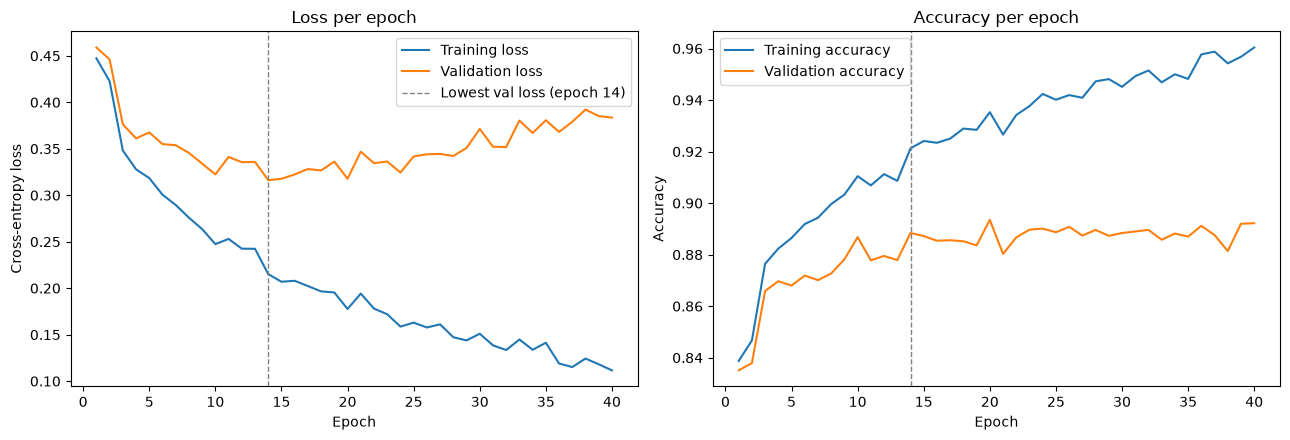

Lowest validation loss at epoch 14: 0.3162


,train acc,val acc,acc gap,train loss,val loss,loss gap
epoch,,,,,,
1,0.8387,0.8351,0.0036,0.4473,0.4590,0.0116
5,0.8865,0.8680,0.0185,0.3185,0.3676,0.0491
10,0.9105,0.8868,0.0237,0.2474,0.3224,0.0750
14,0.9213,0.8884,0.0329,0.2151,0.3162,0.1010
20,0.9353,0.8935,0.0418,0.1776,0.3178,0.1401
30,0.9451,0.8884,0.0567,0.1510,0.3714,0.2204
40,0.9604,0.8922,0.0682,0.1116,0.3835,0.2719


In [9]:
epochs_axis = np.arange(1, EPOCHS + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(epochs_axis, history["train_loss"], label="Training loss")
ax1.plot(epochs_axis, history["val_loss"], label="Validation loss")
ax1.axvline(best_epoch, ls="--", c="gray", lw=1, label=f"Lowest val loss (epoch {best_epoch})")
ax1.set(title="Loss per epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
ax1.legend()

ax2.plot(epochs_axis, history["train_acc"], label="Training accuracy")
ax2.plot(epochs_axis, history["val_acc"], label="Validation accuracy")
ax2.axvline(best_epoch, ls="--", c="gray", lw=1)
ax2.set(title="Accuracy per epoch", xlabel="Epoch", ylabel="Accuracy")
ax2.legend()
plt.tight_layout()
plt.show()

gap = pd.DataFrame({
    "epoch": epochs_axis,
    "train acc": history["train_acc"], "val acc": history["val_acc"],
    "acc gap": np.array(history["train_acc"]) - np.array(history["val_acc"]),
    "train loss": history["train_loss"], "val loss": history["val_loss"],
    "loss gap": np.array(history["val_loss"]) - np.array(history["train_loss"]),
}).set_index("epoch")
print(f"Lowest validation loss at epoch {best_epoch}: {min(history['val_loss']):.4f}")
gap.iloc[[0, 4, 9, best_epoch - 1, 19, 29, 39]].drop_duplicates().round(4)

### 2.4 How the gap between training and validation evolves

In the first few epochs the training and validation performance are almost identical. At epoch 1 they differ by only about 0.4 percentage points of accuracy which shows the model is still learning general patterns. As training continues, training loss keeps falling but validation loss bottoms out around **epoch 14 (≈ 0.316)** and then creeps back up to ≈ 0.38 by epoch 40. Meanwhile validation accuracy plateaus at about 88.5 to 89% while training accuracy climbs to about 96%. The accuracy gap therefore widens steadily from about 2 points at epoch 10 to about 4 at epoch 20 and about 7 at epoch 40. This is classic **overfitting**. After roughly 15 epochs the network is memorising the training images rather than learning features that generalise.

### 2.5 Hyperparameter comparison using the validation set only

To make the final configuration a justified choice rather than a default, we compare several training settings for the same 784 → 128 → 10 network. Every configuration is scored only on the **validation set**, so the test set stays untouched until Task 3.

The search runs in two stages to keep the runtime reasonable.

1. **Stage A** compares learning rate and batch size with no regularisation, for 30 epochs each.
2. **Stage B** takes the best learning rate and batch size from Stage A and compares regularisation options (dropout on the hidden layer and L2 weight decay), for 40 epochs each.

Each run is scored by its **lowest validation loss** over all epochs, and the epoch where that happens becomes its early-stopping point.

In [10]:
def run_config(lr, batch_size, dropout=0.0, weight_decay=0.0, epochs=30):
    torch.manual_seed(SEED)
    m = build_model(dropout)
    h = train(m, epochs, lr=lr, batch_size=batch_size,
              weight_decay=weight_decay, verbose=False)
    best = int(np.argmin(h["val_loss"]))
    summary = {
        "lr": lr, "batch size": batch_size, "dropout": dropout, "weight decay": weight_decay,
        "best epoch": best + 1,
        "best val loss": h["val_loss"][best],
        "val acc @ best": h["val_acc"][best],
        "acc gap @ best": h["train_acc"][best] - h["val_acc"][best],
        "acc gap @ last": h["train_acc"][-1] - h["val_acc"][-1],
    }
    return summary, h

t0 = time.time()
stage_a = []
for lr in [3e-3, 1e-3, 3e-4]:
    for bs in [64, 128]:
        s, _ = run_config(lr, bs, epochs=30)
        stage_a.append(s)
        print(f"lr={lr:<7g} batch={bs:<4d} best val loss {s['best val loss']:.4f} "
              f"(epoch {s['best epoch']}), val acc {s['val acc @ best']:.4f}")
print(f"\nStage A time: {time.time() - t0:.0f} s")

stage_a_df = (pd.DataFrame(stage_a).drop(columns=["dropout", "weight decay"])
              .sort_values("best val loss").reset_index(drop=True))
stage_a_df.round(4)

lr=0.003   batch=64   best val loss 0.3302 (epoch 10), val acc 0.8845


lr=0.003   batch=128  best val loss 0.3275 (epoch 7), val acc 0.8808


lr=0.001   batch=64   best val loss 0.3162 (epoch 14), val acc 0.8884


lr=0.001   batch=128  best val loss 0.3160 (epoch 24), val acc 0.8885


lr=0.0003  batch=64   best val loss 0.3169 (epoch 30), val acc 0.8894


lr=0.0003  batch=128  best val loss 0.3294 (epoch 28), val acc 0.8801

Stage A time: 246 s


,lr,batch size,best epoch,best val loss,val acc @ best,acc gap @ best,acc gap @ last
0,0.0010,128,24,0.3160,0.8885,0.0467,0.0488
1,0.0010,64,14,0.3162,0.8884,0.0329,0.0567
2,0.0003,64,30,0.3169,0.8894,0.0329,0.0329
3,0.0030,128,7,0.3275,0.8808,0.0237,0.0577
4,0.0003,128,28,0.3294,0.8801,0.0272,0.0269
5,0.0030,64,10,0.3302,0.8845,0.0297,0.0517


In [11]:
best_a = stage_a_df.iloc[0]
BEST_LR, BEST_BS = float(best_a["lr"]), int(best_a["batch size"])
print(f"Best from Stage A: lr={BEST_LR:g}, batch size={BEST_BS}\n")

reg_options = {
    "No regularisation": dict(dropout=0.0, weight_decay=0.0),
    "Dropout 0.2": dict(dropout=0.2, weight_decay=0.0),
    "Weight decay 1e-4": dict(dropout=0.0, weight_decay=1e-4),
    "Dropout 0.2 + weight decay 1e-4": dict(dropout=0.2, weight_decay=1e-4),
}

t0 = time.time()
stage_b, stage_b_hist = [], {}
for name, opts in reg_options.items():
    s, h = run_config(BEST_LR, BEST_BS, epochs=40, **opts)
    stage_b.append({"configuration": name, **s})
    stage_b_hist[name] = h
    print(f"{name:32s} best val loss {s['best val loss']:.4f} (epoch {s['best epoch']}), "
          f"val acc {s['val acc @ best']:.4f}, gap at epoch 40 {s['acc gap @ last']:.4f}")
print(f"\nStage B time: {time.time() - t0:.0f} s")

stage_b_df = (pd.DataFrame(stage_b).set_index("configuration")
              .drop(columns=["lr", "batch size"]).sort_values("best val loss"))
stage_b_df.round(4)

Best from Stage A: lr=0.001, batch size=128



No regularisation                best val loss 0.3160 (epoch 24), val acc 0.8885, gap at epoch 40 0.0611


Dropout 0.2                      best val loss 0.3063 (epoch 21), val acc 0.8892, gap at epoch 40 0.0523


Weight decay 1e-4                best val loss 0.3090 (epoch 24), val acc 0.8887, gap at epoch 40 0.0541


Dropout 0.2 + weight decay 1e-4  best val loss 0.3061 (epoch 40), val acc 0.8896, gap at epoch 40 0.0460

Stage B time: 399 s


,dropout,weight decay,best epoch,best val loss,val acc @ best,acc gap @ best,acc gap @ last
configuration,,,,,,,
Dropout 0.2 + weight decay 1e-4,0.2,0.0001,40,0.3061,0.8896,0.0460,0.0460
Dropout 0.2,0.2,0.0000,21,0.3063,0.8892,0.0346,0.0523
Weight decay 1e-4,0.0,0.0001,24,0.3090,0.8887,0.0397,0.0541
No regularisation,0.0,0.0000,24,0.3160,0.8885,0.0467,0.0611


### 2.6 Effect of regularisation on overfitting

The plots compare the four Stage B runs. The left panel shows validation loss and the right panel shows the gap between training and validation accuracy, so a lower and flatter line means less overfitting.

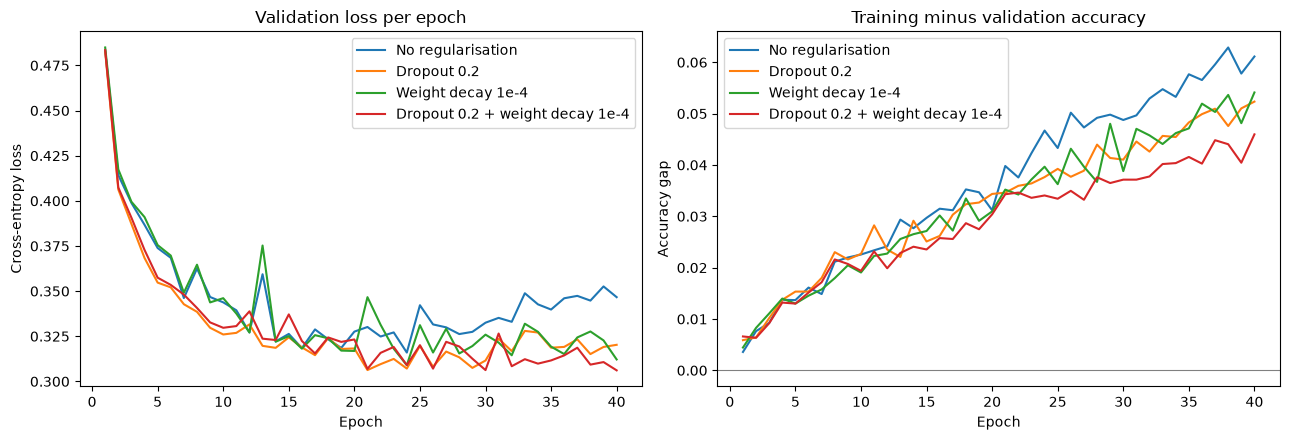

In [12]:
ep = np.arange(1, 41)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in stage_b_hist.items():
    ax1.plot(ep, h["val_loss"], label=name)
    ax2.plot(ep, np.array(h["train_acc"]) - np.array(h["val_acc"]), label=name)
ax1.set(title="Validation loss per epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
ax2.set(title="Training minus validation accuracy", xlabel="Epoch", ylabel="Accuracy gap")
ax2.axhline(0, c="gray", lw=0.8)
ax1.legend(); ax2.legend()
plt.tight_layout()
plt.show()

**What the comparison shows**

* **Stage A.** Learning rate 1e-3 with batch size 64 or 128, and learning rate 3e-4 with batch size 64, all reach almost the same best validation loss (about 0.316 to 0.317). The differences are smaller than the normal run-to-run noise, so these settings are effectively tied. A learning rate of 3e-3 is clearly worse because it is too large and the loss becomes unstable. We continue with learning rate 1e-3 and batch size 128 because it has the lowest validation loss.
* **Stage B.** Every regularisation option improves on the unregularised run. Dropout 0.2 lowers the best validation loss from 0.316 to 0.306, and weight decay alone lowers it to 0.309. Combining the two gives the lowest validation loss (0.306) and the highest validation accuracy (89.0%).
* **Overfitting.** Regularisation shrinks the gap between training and validation accuracy at epoch 40 from 6.1 points without regularisation to 4.6 points with dropout and weight decay combined. The unregularised validation loss starts rising after about epoch 24, while the combined run is still improving at epoch 40. Regularisation does not remove overfitting completely, but it clearly slows it down.

### 2.7 Chosen configuration

The final configuration keeps the required **784 → 128 → 10** architecture and adds **dropout 0.2** on the hidden layer and **weight decay 1e-4**. It is trained with Adam at learning rate **1e-3** with batch size **128** for **40 epochs**. This configuration had the lowest validation loss in Stage B. Its validation loss was still slowly falling at epoch 40, so we stop there to stay within the 20 to 40 epoch range of the brief. The cell below reads these values from the comparison tables so the choice is fully reproducible.

In [13]:
BEST_NAME = stage_b_df.index[0]
BEST_CFG = {**reg_options[BEST_NAME], "lr": BEST_LR, "batch_size": BEST_BS}
BEST_EPOCH = int(stage_b_df.loc[BEST_NAME, "best epoch"])
print("Chosen configuration:", BEST_NAME, BEST_CFG, "| epochs:", BEST_EPOCH)

Chosen configuration: Dropout 0.2 + weight decay 1e-4 {'dropout': 0.2, 'weight_decay': 0.0001, 'lr': 0.001, 'batch_size': 128} | epochs: 40


---
## Task 3 Model Evaluation and Error Analysis

### 3.1 Training the chosen configuration

The final model uses the configuration selected in section 2.7 and is retrained from scratch with the same seed for its early-stopping epoch count. Every choice so far was made using only the validation set, so the test set is still unseen.

In [14]:
torch.manual_seed(SEED)
final_model = build_model(BEST_CFG["dropout"])
final_hist = train(final_model, BEST_EPOCH, lr=BEST_CFG["lr"], batch_size=BEST_CFG["batch_size"],
                   weight_decay=BEST_CFG["weight_decay"], verbose=False)
print(final_model)
print(f"Final model trained for {BEST_EPOCH} epochs | "
      f"val loss {final_hist['val_loss'][-1]:.4f}, val acc {final_hist['val_acc'][-1]:.4f}")

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Final model trained for 40 epochs | val loss 0.3061, val acc 0.8896


### 3.2 Test-set evaluation (run once)
With the final model chosen we evaluate it exactly once on the untouched test set. The resulting accuracy is our unbiased estimate of real-world performance.


In [15]:
final_model.eval()
with torch.no_grad():
    test_logits = final_model(Xte_t)
    test_probs = torch.softmax(test_logits, dim=1).numpy()   # softmax output layer
y_pred = test_probs.argmax(1)

test_acc = (y_pred == y_test).mean()
print(f"TEST ACCURACY: {test_acc:.4f}  ({(y_pred == y_test).sum()} / {len(y_test)} correct)")

TEST ACCURACY: 0.8939  (8939 / 10000 correct)


### 3.3 Confusion matrix
The confusion matrix shows how often each true class is predicted as each other class. Large off-diagonal values reveal the pairs the model mixes up most.


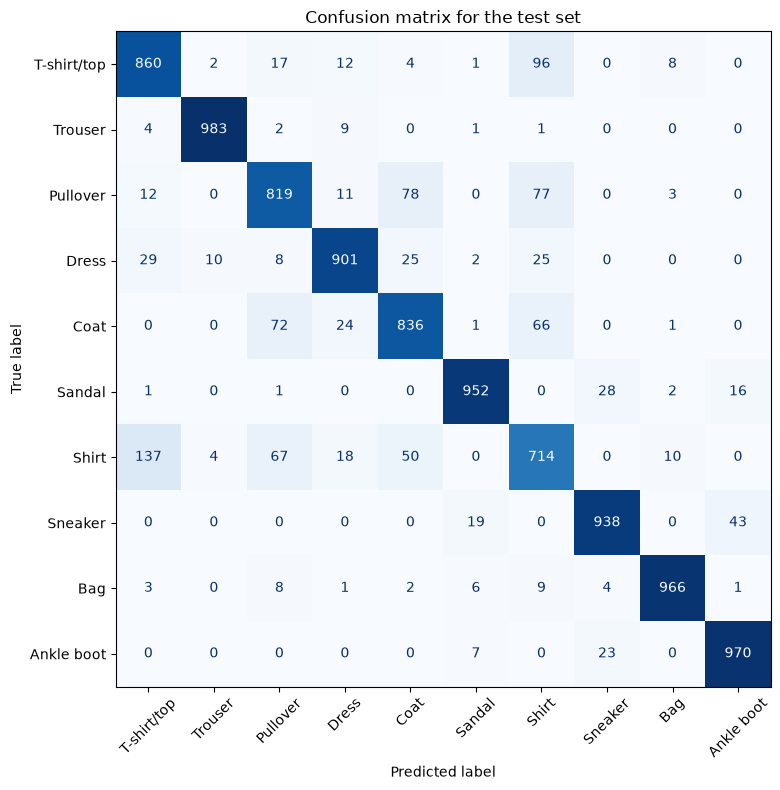

Most frequent confusions from true to predicted
  Shirt        -> T-shirt/top : 137
  T-shirt/top  -> Shirt       : 96
  Pullover     -> Coat        : 78
  Pullover     -> Shirt       : 77
  Coat         -> Pullover    : 72


In [16]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d")
ax.set_title("Confusion matrix for the test set")
plt.tight_layout()
plt.show()

# Largest off-diagonal confusions
off = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(10) if i != j]
print("Most frequent confusions from true to predicted")
for n, t, p in sorted(off, reverse=True)[:5]:
    print(f"  {t:12s} -> {p:12s}: {n}")

### 3.4 Per-class precision and recall
Precision measures how often a predicted class is correct while recall measures how often a true class is found. Reporting both per class shows which categories the model handles well and which it misses.


In [17]:
prec, rec, f1, support = precision_recall_fscore_support(y_test, y_pred)
metrics = pd.DataFrame({"precision": prec, "recall": rec, "f1-score": f1, "support": support},
                       index=CLASS_NAMES).round(3)
display(metrics.sort_values("recall"))

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

,precision,recall,f1-score,support
Shirt,0.723,0.714,0.718,1000
Pullover,0.824,0.819,0.821,1000
Coat,0.840,0.836,0.838,1000
T-shirt/top,0.822,0.860,0.841,1000
Dress,0.923,0.901,0.912,1000
Sneaker,0.945,0.938,0.941,1000
Sandal,0.963,0.952,0.957,1000
Bag,0.976,0.966,0.971,1000
Ankle boot,0.942,0.970,0.956,1000
Trouser,0.984,0.983,0.983,1000


              precision    recall  f1-score   support

 T-shirt/top      0.822     0.860     0.841      1000
     Trouser      0.984     0.983     0.983      1000
    Pullover      0.824     0.819     0.821      1000
       Dress      0.923     0.901     0.912      1000
        Coat      0.840     0.836     0.838      1000
      Sandal      0.963     0.952     0.957      1000
       Shirt      0.723     0.714     0.718      1000
     Sneaker      0.945     0.938     0.941      1000
         Bag      0.976     0.966     0.971      1000
  Ankle boot      0.942     0.970     0.956      1000

    accuracy                          0.894     10000
   macro avg      0.894     0.894     0.894     10000
weighted avg      0.894     0.894     0.894     10000



### 3.5 Misclassified examples
We display a random sample of test images the model got wrong together with their true and predicted labels. Inspecting these errors shows whether the mistakes are reasonable or caused by a clear model weakness.


1061 misclassified test images; showing 15 random examples


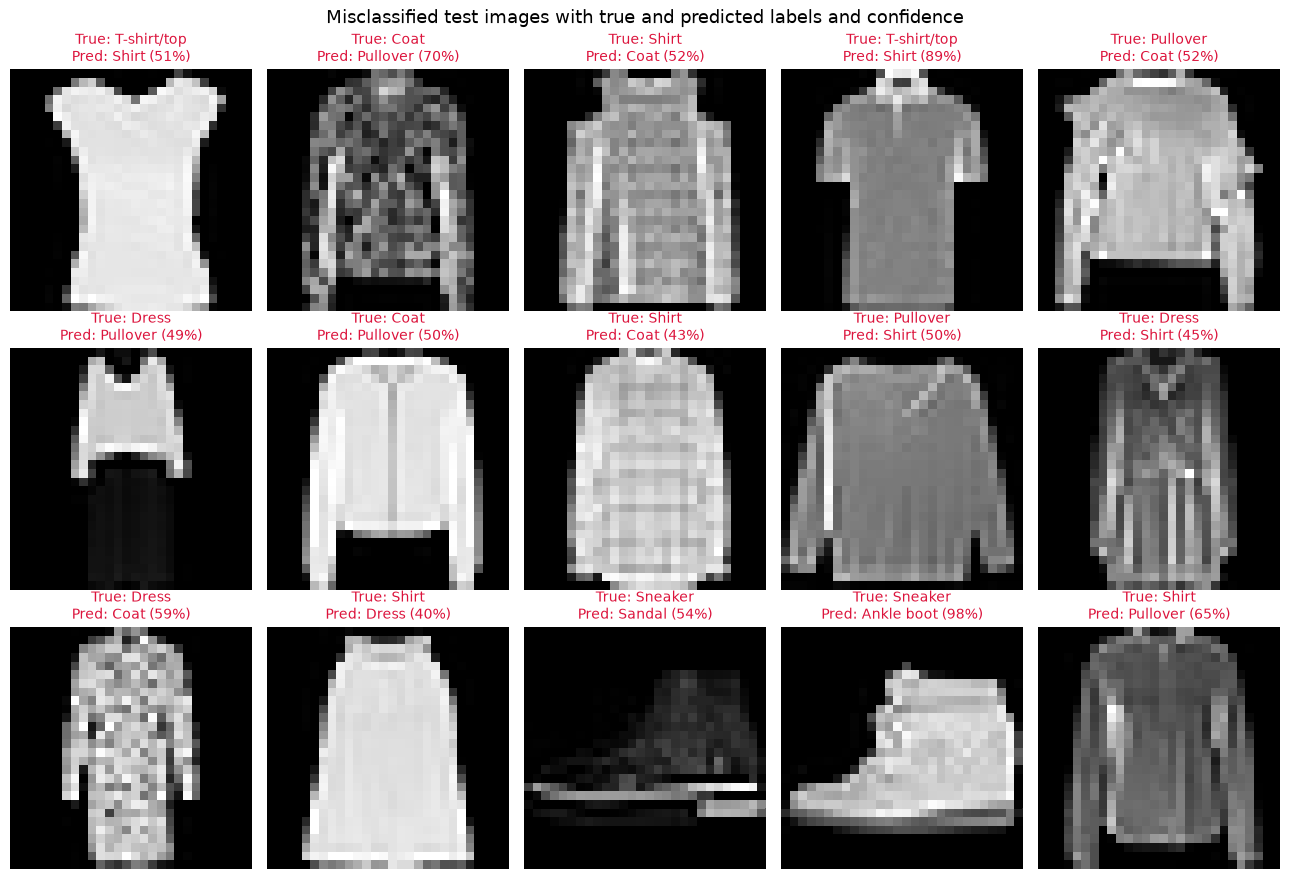

In [18]:
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} misclassified test images; showing 15 random examples")

rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=15, replace=False)

fig, axes = plt.subplots(3, 5, figsize=(13, 9))
for ax, i in zip(axes.flat, show):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[y_pred[i]]}"
                 f" ({test_probs[i, y_pred[i]]:.0%})", fontsize=10, color="crimson")
    ax.axis("off")
fig.suptitle("Misclassified test images with true and predicted labels and confidence", fontsize=13)
plt.tight_layout()
plt.show()

### 3.6 Error analysis summary

* **Test accuracy is 89.4%** (8,939 / 10,000), up from 88.7% for the unregularised 14-epoch model in the first version of this notebook. It is close to the 89.0% validation accuracy, so the validation set was a reliable estimate of performance on unseen data.
* **Easy classes are** Trouser, Bag, Ankle boot, Sandal and Sneaker which all score above 93% recall with high precision. Their silhouettes are distinctive.
* **The hardest class is Shirt** with precision ≈ 0.72 and recall ≈ 0.71, followed by Pullover (recall ≈ 0.82) and Coat (recall ≈ 0.84). Most errors are confusions among upper-body garments such as Shirt and T-shirt/top, Pullover and Coat, and Pullover and Shirt. These items share almost the same outline at 28 × 28 resolution and what tells them apart (collars, buttons, sleeve length and texture) is subtle.
* **Regularisation helped most for Pullover**, whose recall rose from about 0.74 to 0.82, while Shirt stayed at roughly the same level. This suggests that the Shirt errors come from the limits of the model and the image resolution rather than from overfitting.
* Many of the misclassified images above are genuinely ambiguous even to a human and some of them are predicted with high confidence.
* **The model struggles because** a fully connected network treats the 784 pixels as an unordered list so it cannot exploit local spatial structure such as edges and textures. A convolutional neural network (CNN) would be the natural next step for reducing these confusions.

---
## 4. Conclusion

* A small fully connected network with a single hidden layer of 128 neurons reaches **89.4% test accuracy** on Fashion-MNIST using only flattened, scaled pixels.
* Without regularisation the network starts **overfitting after about 15 to 25 epochs**. Training accuracy keeps climbing towards 96% while validation loss rises.
* A validation-only comparison showed that learning rates around 1e-3 work best. Adding **dropout and weight decay** lowered the validation loss, reduced the overfitting gap and improved test accuracy by about 0.7 points without changing the 784 → 128 → 10 architecture.
* The main remaining weakness is **upper-body garments**, especially Shirt with about 71% recall. The model cannot reliably tell these classes apart from their overall shape alone.
* **Next steps** would be a convolutional network that can use spatial patterns, data augmentation such as small shifts and flips, and repeating the final training with several random seeds to report a mean and spread for the test accuracy.